# Devoir n° 1 : Introduction et capacité d'apprentissage

### 1. Introduction et objectifs

L'objectif de ce travail est d'étudier comment un ordinateur peut apprendre à classer des données à l'aide d'un algorithme appelé ERM (*Empirical Risk Minimization*).

Nous allons utiliser un classificateur à seuil. Il sépare les données en deux classes : 0 et 1, selon la valeur de *x*.

Nous étudierons deux situations :

- **Le cas PAC réalisable :** les étiquettes sont correctes et suivent toutes la même règle
- **Le cas Agnostic PAC :** certaines étiquettes sont inversées aléatoirement, c'est-à-dire que les données contiennent du bruit

Nous allons ensuite comparer les résultats pour comprendre si l'ordinateur apprend mieux lorsqu'il dispose de davantage d'exemples et comment le bruit influence son apprentissage.

In [286]:
# Importation des bibliothèques
import numpy as np                # pour les calculs et la génération aléatoire
import matplotlib.pyplot as plt   # pour les graphiques

# Paramètres communs aux expériences
Theta = 0.5
tailles_echantillon = [5, 10, 20, 50, 100, 200]

# Permet de reproduire les mêmes tirages aléatoires
np.random.seed(42)


### 2. Génération des données

Nous considérons un seuil cible Theta = 0.5. 

La fonction `fonction_cible` attribue l'étiquette 0 si x ≤ Theta et l'étiquette 1 si x > Theta. 
<br>La fonction `generation_donnees` génère m valeurs aléatoires dans [0, 1], calcule leurs étiquettes et renvoie les deux tableaux X et y. Ainsi X[i] et y[i] correspondent toujours au même exemple.</br>

In [287]:
# Correspond à la fonction cible de l'énoncé
def fonction_cible(x, Theta):
    # Renvoie 0 si x <= Theta et 1 si x > Theta
    return(x > Theta).astype(int)

# Génère m exemples avec un seuil Theta
def generation_donnees(m, Theta):
    # Génère m entrées indépendantes et leurs étiquettes sans bruit
    X = np.random.uniform(0, 1, m)
    y = fonction_cible(X, Theta)
    return X,y

# Génére et stocke un échantillon pour chaque taille demandée
jeux_donnees = {}

for m in tailles_echantillon:
    X, y = generation_donnees(m, Theta)
    jeux_donnees[m] = (X, y)

**Visualisation d'un échantillon**

Le graphique représente les 20 exemples de l'échantillon de taille m = 20. 
<br>Chaque point est placé horizontalement selon sa valeur X et verticalement selon son étiquette y.</br>
<br>La ligne pointillée indique le seuil cible Theta = 0.5 : les points situés à gauche ou sur ce seuil ont l'étiquette 0, et ceux situés à droite ont l'étiquette 1. </br>

Cette représentation permet de vérifier visuellement que les données suivent la fonction cible.


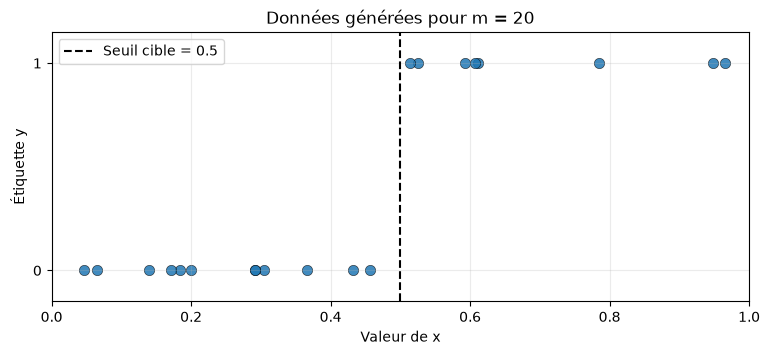

In [288]:
# Afficher le jeu de données déjà généré et stocké contenant 20 exemples
X, y = jeux_donnees[20]

plt.figure(figsize=(9, 3.5))

plt.scatter(X, y, s=55, alpha=0.85, edgecolors="black", linewidths=0.4)
plt.axvline(Theta, color="black", linestyle="--", label=f"Seuil cible = {Theta}")
plt.xlabel("Valeur de x")
plt.ylabel("Étiquette y")
plt.title("Données générées pour m = 20")
plt.yticks([0, 1], ["0", "1"])
plt.ylim(-0.15, 1.15)
plt.xlim(0, 1)
plt.grid(alpha=0.25)
plt.legend()
plt.show()

### 3. Implémentation de l'algorithme ERM

L'algorithme ERM (*Empirical Risk Minimization*) cherche le seuil qui minimise l'erreur empirique, c'est-à-dire la proportion d'étiquettes mal prédites dans l'échantillon d'entraînement. 

Pour trouver ce seuil, nous trions les valeurs de X et testons les milieux entre deux valeurs consécutives, ainsi que les bornes 0 et 1.
Cette méthode suffit, car les prédictions ne changent que lorsque le seuil passe d’un côté à l’autre d’une valeur de l’échantillon. Tester les milieux entre deux valeurs consécutives permet donc de considérer les différentes séparations possibles entre les exemples.

Ce tri sert uniquement à construire les seuils candidats : les prédictions sont calculées avec les tableaux originaux X et y, qui restent donc correctement associés.

In [289]:
def classificateur_seuil(X, seuil):
    # Prédit 0 si X <= seuil, et 1 si X > seuil.
    return (X > seuil).astype(int)


def erm(X, y):    
    # Trie les valeurs de X dans l'ordre croissant pour déterminer les possibles seuils
    X_trie = np.sort(X)
    
    seuils = np.concatenate((
        [0.0],
        (X_trie[:-1] + X_trie[1:]) / 2,
        [1.0]
    ))
    
    meilleure_erreur = float("inf")
    meilleur_seuil = None

    # Choisit le seuil qui donne le moins d'erreurs sur l'entraînement
    for seuil in seuils:
        predictions = classificateur_seuil(X, seuil)
        erreur = np.mean(predictions != y)
        
        if erreur < meilleure_erreur:
            meilleure_erreur = erreur
            meilleur_seuil = seuil
    
    return meilleur_seuil, meilleure_erreur

### 4. Evaluation des performances

L'erreur empirique est calculée sur les données qui ont servi à apprendre le seuil. En effet, un classificateur peut avoir une erreur empirique nulle sans pour autant connaître exactement le seuil cible. Il peut avoir appris à partir d'un échantillon trop petit pour représenter toutes les situations possibles.

Pour estimer l'erreur réelle, nous évaluons ce seuil sur un nouvel échantillon indépendant de 10 000 exemples, généré sans bruit. 
<br>Ce test donne une estimation de la performance sur de nouvelles données. Nous comparons ces deux erreurs pour chacune des tailles d'échantillon.</br>

In [290]:
def erreur_reelle_estimee(seuil_appris, Theta, taille_test=10000):
    # Générer de nouvelles données indépendantes
    X_test = np.random.uniform(0, 1, taille_test)

    # Calculer les vraies étiquettes
    y_test = fonction_cible(X_test, Theta)

    # Prédire les étiquettes avec le seuil appris
    predictions = classificateur_seuil(X_test, seuil_appris)

    # Calculer la proportion d'erreurs
    erreur = np.mean(predictions != y_test)
    return erreur

print(f"{'m':>5} | {'Seuil appris':>12} | {'Erreur empirique':>17} | {'Erreur test estimée':>20}")
print("-" * 65)

for m, (X, y) in jeux_donnees.items():
    seuil_appris, erreur_empirique = erm(X, y)
    erreur_test = erreur_reelle_estimee(seuil_appris, Theta)
    print(f"{m:5d} | {seuil_appris:12.4f} | {erreur_empirique:17.4f} | {erreur_test:20.4f}")


    m | Seuil appris |  Erreur empirique |  Erreur test estimée
-----------------------------------------------------------------
    5 |       0.4866 |            0.0000 |               0.0136
   10 |       0.4067 |            0.0000 |               0.0944
   20 |       0.4852 |            0.0000 |               0.0149
   50 |       0.5076 |            0.0000 |               0.0088
  100 |       0.5000 |            0.0000 |               0.0002
  200 |       0.4970 |            0.0000 |               0.0036


Dans le cas sans bruit, l’erreur empirique est nulle pour toutes les tailles d’échantillon, car les étiquettes suivent exactement la fonction cible. En revanche, l’erreur test peut rester positive, surtout lorsque l’échantillon est petit. En effet, le seuil appris à partir des données n’est pas forcément exactement égal au seuil cible. Avec davantage d’exemples, le seuil appris est généralement plus précis.

### 5. Vérification expérimentale de l'apprentissage PAC

Nous choisissons epsilon = 0.15, ce qui correspond à une erreur de 15 %, et delta = 0.05, soit un repère de probabilité d'échec de 5 %. 
<br>Ce sont des paramètres choisis pour l'expérience : ils ne sont pas calculés par l'algorithme. Nous cherchons à savoir à quelle fréquence l'erreur réelle dépasse 15 %, puis à observer comment cette fréquence évolue quand la taille de l'échantillon augmente.</br>

Pour chaque taille m, nous répétons l'expérience 500 fois. À chaque répétition, nous générons un nouvel échantillon d'entraînement sans bruit, nous apprenons un seuil avec l'algorithme ERM, puis nous estimons son erreur sur un jeu de test indépendant de 10 000 exemples. Nous calculons ensuite l'erreur test moyenne et la proportion de répétitions où l'erreur test dépasse epsilon. Cette proportion fournit une estimation expérimentale de P(L(h)>epsilon).

In [291]:
epsilon = 0.15
delta = 0.05
nombre_repetitions = 500
taille_test = 10000

resultats_repetitions = []
probabilites = []

for m in tailles_echantillon:
    erreurs = []

    for repetition in range(nombre_repetitions):
        X_train, y_train = generation_donnees(m, Theta)
        seuil_appris, erreur_empirique = erm(X_train, y_train)
        erreur_test = erreur_reelle_estimee(seuil_appris, Theta, taille_test)
        erreurs.append(erreur_test)

    erreurs = np.array(erreurs)
    resultats_repetitions.append(np.mean(erreurs))
    probabilites.append(np.mean(erreurs > epsilon))

    print(
        f"m = {m:3d} | "
        f"Erreur moyenne = {np.mean(erreurs):.4f} | "
        f"P(L(h) > {epsilon}) estimée = {np.mean(erreurs > epsilon):.3f}"
    )

m =   5 | Erreur moyenne = 0.0935 | P(L(h) > 0.15) estimée = 0.152
m =  10 | Erreur moyenne = 0.0469 | P(L(h) > 0.15) estimée = 0.028
m =  20 | Erreur moyenne = 0.0241 | P(L(h) > 0.15) estimée = 0.000
m =  50 | Erreur moyenne = 0.0097 | P(L(h) > 0.15) estimée = 0.000
m = 100 | Erreur moyenne = 0.0049 | P(L(h) > 0.15) estimée = 0.000
m = 200 | Erreur moyenne = 0.0025 | P(L(h) > 0.15) estimée = 0.000


**Interprétation du cas réalisable**

Les résultats montrent que l'erreur test moyenne estimée diminue lorsque la taille de l'échantillon augmente. 
<br>Elle passe de 0,0935, soit 9,35 %, pour m=5, à 0,0025, soit 0,25 %, pour m=200.</br>

C'est logique : un petit échantillon donne peu d'informations sur la position exacte du seuil cible. 
<br>Avec davantage d'exemples, l'algorithme ERM peut généralement choisir un seuil plus proche de Theta=0.5, ce qui améliore ses prédictions sur de nouvelles données.</br>

Dans cette expérience, les étiquettes suivent toutes la fonction cible et ne sont pas bruitées. Nous sommes donc dans le cas réalisable. L'erreur empirique peut être nulle alors que l'erreur test ne l'est pas : le seuil peut classer correctement les exemples d'entraînement sans être exactement égal au seuil cible.

**Visualisation de la probabilité d'échec**

La probabilité affichée est estimée par la proportion des 500 répétitions où l'erreur test dépasse epsilon=0.15, c'est-à-dire 15 %. 
<br>La ligne horizontale représente delta=0.05, un repère fixé à 5 % pour comparer les résultats.</br>

Une estimation égale à zéro signifie qu'aucun dépassement n'a été observé pendant les 500 répétitions. Cela ne prouve pas que la probabilité réelle est exactement nulle : un événement rare peut simplement ne pas s'être produit au cours de cette expérience.

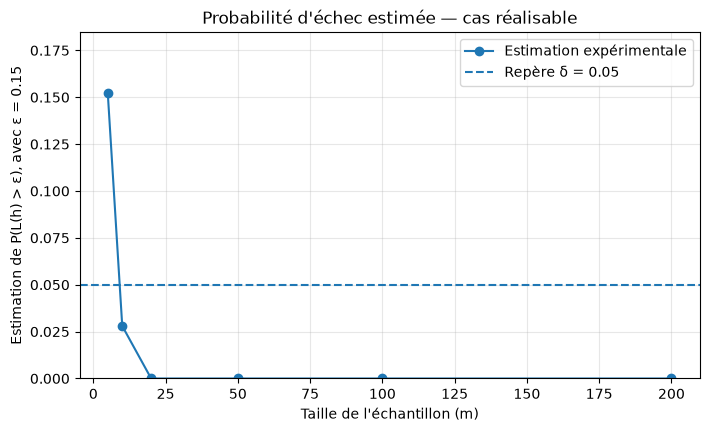

In [292]:
plt.figure(figsize=(8, 4.5))
plt.plot(tailles_echantillon, probabilites, marker="o", label="Estimation expérimentale")
plt.axhline(delta, linestyle="--", label=f"Repère δ = {delta}")
plt.xlabel("Taille de l'échantillon (m)")
plt.ylabel(r"Estimation de P(L(h) > ε), avec ε = 0.15")
plt.title("Probabilité d'échec estimée — cas réalisable")
plt.ylim(0, min(1, max(max(probabilites), delta) * 1.15 + 0.01))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

**Interprétation**

Dans le cas réalisable, la probabilité estimée que l'erreur test dépasse 15 % diminue lorsque la taille de l'échantillon augmente. Pour m=5, elle vaut 0,152, soit 15,2 %. Pour m=10, elle descend à 0,028, soit 2,8 %. À partir de m=20, aucun dépassement de 15 % n'a été observé dans les 500 répétitions.

Le repère delta=0.05 permet de situer ces estimations : le résultat pour m=5 est supérieur à 5 %, tandis que celui pour m=10 est déjà inférieur à ce repère. Pour les tailles suivantes, la fréquence observée est nulle dans cette expérience.

Ces observations vont dans le sens de l'idée PAC : avec davantage de données d'entraînement, le classificateur a généralement plus de chances d'obtenir une faible erreur de généralisation. Il faut toutefois garder à l'esprit que les probabilités sont estimées à partir de 500 répétitions et qu'une fréquence observée de zéro ne signifie pas que le risque réel est forcément nul.

### 6. Du PAC à l'Agnostic PAC

Dans cette partie, nous étudions l'effet d'étiquettes bruitées. Nous choisissons eta=0.1 : chaque étiquette est inversée indépendamment avec une probabilité de 10 %. Par exemple, une étiquette qui devrait valoir 0 peut être remplacée par 1, et inversement.

Le classificateur ERM est entraîné sur les données bruitées. Nous évaluons ensuite ses prédictions sur un jeu de test indépendant dont les étiquettes sont soumises au même mécanisme de bruit. L'erreur mesurée correspond donc à la proportion de désaccords avec les étiquettes bruitées du test, et non uniquement avec la fonction cible sans bruit.
Comme dans la partie précédente, nous répétons l'expérience 500 fois pour chaque taille d'échantillon. Nous mesurons l'erreur test moyenne, la proportion d'expériences où l'erreur empirique est nulle, et la probabilité estimée que l'erreur test dépasse epsilon=0.15. Cela permet de comparer plus directement les situations PAC et Agnostic PAC.

In [293]:
def generation_donnees_bruitees(m, Theta, eta):
    X = np.random.uniform(0, 1, m)
    y = fonction_cible(X, Theta)
    inversions = np.random.random(m) < eta
    y = np.where(inversions, 1 - y, y)
    return X, y


def erreur_reelle_estimee_bruitee(seuil_appris, Theta, eta, taille_test=10000):
    X_test = np.random.uniform(0, 1, taille_test)
    y_test = fonction_cible(X_test, Theta)

    inversions = np.random.random(taille_test) < eta
    y_test = np.where(inversions, 1 - y_test, y_test)

    predictions = classificateur_seuil(X_test, seuil_appris)
    return np.mean(predictions != y_test)

eta = 0.1
nombre_repetitions_agnostic = 500
resultats_agnostic = []
probabilites_agnostic = []
proportions_erreur_nulle = []

for m in tailles_echantillon:
    erreurs_test = []
    erreurs_empiriques = []

    for repetition in range(nombre_repetitions_agnostic):
        X_train, y_train = generation_donnees_bruitees(m, Theta, eta)
        seuil_appris, erreur_empirique = erm(X_train, y_train)
        erreur_test = erreur_reelle_estimee_bruitee(
            seuil_appris, Theta, eta, taille_test
        )
        erreurs_empiriques.append(erreur_empirique)
        erreurs_test.append(erreur_test)

    erreur_moyenne = np.mean(erreurs_test)
    proportion_nulle = np.mean(np.array(erreurs_empiriques) == 0)
    probabilite_echec = np.mean(np.array(erreurs_test) > epsilon)
    probabilites_agnostic.append(probabilite_echec)

    resultats_agnostic.append(erreur_moyenne)
    proportions_erreur_nulle.append(proportion_nulle)

    print(
    f"m = {m:3d} | "
    f"Erreur test moyenne = {erreur_moyenne:.4f} | "
    f"Proportion d'erreur empirique nulle = {proportion_nulle:.3f} | "
    f"P(L(h) > {epsilon}) estimée = {probabilite_echec:.3f}"
    )

m =   5 | Erreur test moyenne = 0.2193 | Proportion d'erreur empirique nulle = 0.740 | P(L(h) > 0.15) estimée = 0.596
m =  10 | Erreur test moyenne = 0.1737 | Proportion d'erreur empirique nulle = 0.422 | P(L(h) > 0.15) estimée = 0.452
m =  20 | Erreur test moyenne = 0.1372 | Proportion d'erreur empirique nulle = 0.184 | P(L(h) > 0.15) estimée = 0.246
m =  50 | Erreur test moyenne = 0.1168 | Proportion d'erreur empirique nulle = 0.002 | P(L(h) > 0.15) estimée = 0.058
m = 100 | Erreur test moyenne = 0.1085 | Proportion d'erreur empirique nulle = 0.000 | P(L(h) > 0.15) estimée = 0.018
m = 200 | Erreur test moyenne = 0.1043 | Proportion d'erreur empirique nulle = 0.000 | P(L(h) > 0.15) estimée = 0.000


### 7. Comparaison des résultats — PAC et Agnostic PAC

Dans le cas réalisable, sans bruit, l'erreur test moyenne estimée diminue nettement lorsque la taille de l'échantillon augmente : elle passe de 9,35 % pour m=5 à 0,25 % pour m=200. Les étiquettes sont toutes produites par la même fonction cible, ce qui permet au seuil appris de se rapprocher du seuil cible à mesure que les données deviennent plus nombreuses.

Dans le cas Agnostic PAC, où chaque étiquette est inversée avec une probabilité eta=0.1, l'erreur test moyenne diminue elle aussi. Elle passe de 21,93 % pour m=5 à 10,43 % pour m=200. L'augmentation de la taille de l'échantillon améliore donc encore la généralisation. Cependant, l'erreur se rapproche de 10 % plutôt que de zéro, car les étiquettes du jeu de test sont elles aussi bruitées : même un seuil bien appris peut être en désaccord avec une étiquette qui a été inversée aléatoirement.

La probabilité estimée que l'erreur test dépasse epsilon=0.15 diminue également dans les deux expériences. Sans bruit, elle passe de 15,2 % pour m=5 à 2,8 % pour m=10, puis aucun dépassement n'est observé à partir de m=20 dans les 500 répétitions. Avec bruit, elle passe de 59,6 % pour m=5 à 45,2 % pour m=10, 24,6 % pour m=20, 5,8 % pour m=50, 1,8 % pour m=100, puis aucun dépassement observé pour m=200. La diminution est donc plus lente avec du bruit, surtout pour les petits échantillons.

L'erreur empirique peut-elle encore être nulle avec du bruit ? Oui. Dans nos expériences, cela arrive dans 74 % des répétitions pour m=5, puis dans 42,2 % pour m=10, 18,4 % pour m=20 et seulement 0,2 % pour m=50. Aucune erreur empirique nulle n'a été observée pour m=100 ou m=200. Sur un petit échantillon, il est possible que les étiquettes bruitées restent compatibles avec un seuil unique. Quand l'échantillon grandit, les inversions aléatoires rendent plus probable la présence d'exemples contradictoires qu'un seul seuil ne peut pas tous classer correctement.

Ces observations illustrent la différence entre les deux cadres. Dans le cas PAC réalisable, les données sont compatibles avec la fonction cible et l'erreur peut se rapprocher de zéro. Dans le cas Agnostic PAC, on peut toujours apprendre à mieux généraliser, mais le bruit impose une limite à la réduction de l'erreur mesurée par rapport aux étiquettes bruitées. Les résultats restent des estimations expérimentales, basées sur 500 répétitions et des jeux de test de 10 000 exemples.

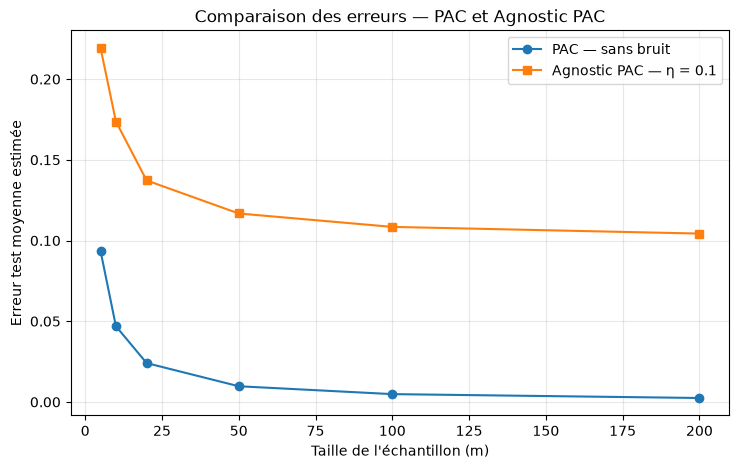

In [294]:
plt.figure(figsize=(8.5, 5))
plt.plot(
    tailles_echantillon, resultats_repetitions,
    marker="o", label="PAC — sans bruit"
)
plt.plot(
    tailles_echantillon, resultats_agnostic,
    marker="s", label=f"Agnostic PAC — η = {eta}"
)
plt.xlabel("Taille de l'échantillon (m)")
plt.ylabel("Erreur test moyenne estimée")
plt.title("Comparaison des erreurs — PAC et Agnostic PAC")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

**Analyse du graphique des erreurs moyennes**

Le graphique montre que l'erreur test moyenne diminue quand la taille de l'échantillon augmente dans les deux situations. La baisse est particulièrement visible dans le cas sans bruit, où l'erreur se rapproche de zéro. Avec du bruit, la courbe descend elle aussi, mais elle se rapproche du niveau de bruit eta=0.1. Cette différence ne signifie pas que l'algorithme cesse d'apprendre : il apprend mieux le seuil, mais il ne peut pas prévoir les inversions aléatoires des étiquettes du jeu de test.

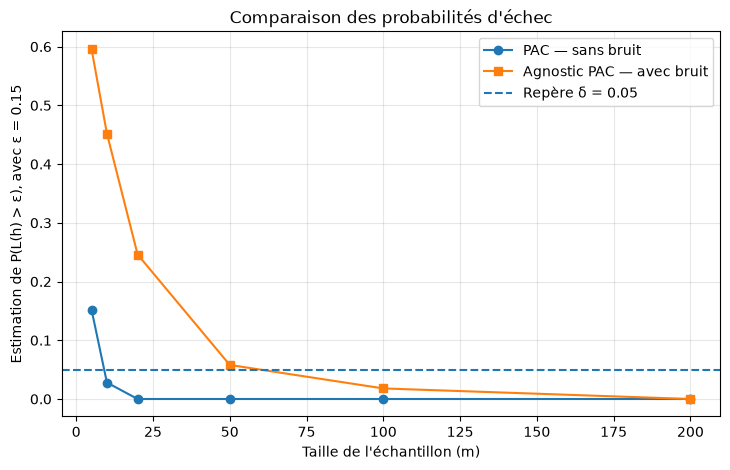

In [295]:
# Comparaison de la probabilité d'obtenir une erreur test supérieure à epsilon
plt.figure(figsize=(8.5, 5))
plt.plot(
    tailles_echantillon, probabilites,
    marker="o", label="PAC — sans bruit"
)
plt.plot(
    tailles_echantillon, probabilites_agnostic,
    marker="s", label="Agnostic PAC — avec bruit"
)
plt.axhline(delta, linestyle="--", label=f"Repère δ = {delta}")
plt.xlabel("Taille de l'échantillon (m)")
plt.ylabel(r"Estimation de P(L(h) > ε), avec ε = 0.15")
plt.title("Comparaison des probabilités d'échec")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


**Analyse du graphique des probabilités d'échec**

La probabilité d'une erreur test supérieure à 15 % diminue à mesure que la taille de l'échantillon augmente. Elle est toutefois plus élevée dans le cas bruité pour les petits échantillons. La ligne delta=0.05 sert de repère : dans les résultats obtenus, la probabilité estimée passe sous ce niveau à partir de m=10 sans bruit, contre m=100 avec bruit. Pour m=200, aucun dépassement n'a été observé dans les 500 répétitions avec ou sans bruit. Cela reste une observation expérimentale, et non une preuve que la probabilité réelle est exactement nulle.

## 8. Conclusion

Ce travail nous a permis de comparer l'apprentissage d'un classificateur à seuil dans deux situations. Nous avons utilisé l'algorithme ERM, qui choisit le seuil donnant le moins d'erreurs sur les exemples d'entraînement, puis nous avons évalué ses performances sur de nouvelles données indépendantes.

Dans le cas réalisable, les étiquettes suivent toutes la fonction cible. Lorsque la taille de l'échantillon augmente, le seuil appris devient généralement plus précis : l'erreur test moyenne passe de 9,35 % pour \(m=5\) à 0,25 % pour \(m=200\). La probabilité estimée d'une erreur supérieure à 15 % diminue elle aussi. Ces résultats illustrent l'idée PAC : avec suffisamment d'exemples, on peut apprendre une hypothèse dont l'erreur de généralisation est faible avec une probabilité élevée.

Dans le cas Agnostic PAC, les étiquettes sont inversées aléatoirement avec une probabilité de 10 %. L'augmentation du nombre d'exemples améliore encore les résultats : l'erreur test moyenne passe de 21,93 % à 10,43 %. Elle ne se rapproche toutefois pas de zéro, mais du niveau de bruit. Le modèle peut apprendre la tendance générale des données, mais il ne peut pas anticiper les inversions aléatoires des étiquettes.

L'erreur empirique peut-elle encore être nulle avec du bruit ? Oui, surtout pour les petits échantillons : elle est nulle dans 74 % des répétitions pour \(m=5\). Cette situation devient rare quand le nombre d'exemples augmente, car les étiquettes inversées rendent plus difficile la classification parfaite de tout l'échantillon.

En conclusion, davantage de données améliore la généralisation dans les deux cadres, mais le bruit change ce que l'on peut espérer atteindre. Dans le cas réalisable, l'erreur peut tendre vers zéro ; dans le cas bruité, une erreur résiduelle subsiste. Enfin, les probabilités présentées dans ce notebook sont des estimations fondées sur 500 répétitions et des jeux de test de 10 000 exemples : elles illustrent les tendances attendues, sans constituer à elles seules une preuve théorique.